# RoBERTa Fine-Tuning

**Environment:** Google Colab | NVIDIA T4 GPU | PyTorch | Hugging Face Transformers

> **Execution note:** This notebook was developed and executed in Google Colab using GPU acceleration. It is not configured for direct local execution without environment and path adjustments.

### Model Configuration
- Base model: `FacebookAI/roberta-base`
- Dataset: HC3 (58,823 training samples)
- Maximum sequence length: 384 tokens
- Fine-tuning: 1 epoch

### Validation Results
- Accuracy: **99.20%**
- Macro F1: **0.9908**
- ROC-AUC: **0.999828**

### Reproducibility
Running this notebook requires the appropriate Python dependencies, access to the training dataset, and updated dataset/model paths. GPU acceleration is recommended.

The fine-tuned model weights are stored separately and are not included in this repository.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/chewy-colab"

os.chdir(PROJECT_ROOT)

print("Current working directory:", os.getcwd())
print("Project folders:", os.listdir("."))

Current working directory: /content/drive/MyDrive/chewy-colab
Project folders: ['notebooks', 'processed', 'models']


In [3]:
!nvidia-smi

Mon Nov  9 22:10:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Explicitly use PyTorch vs Keras
This is a PyTorch-only experiment.

In [9]:
import os

os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

In [10]:
import traceback

try:
    from transformers.models.auto.tokenization_auto import AutoTokenizer
    print("AutoTokenizer imported successfully!")
except Exception:
    traceback.print_exc()

AutoTokenizer imported successfully!


## Load tokenizer and RoBERTa

In [13]:
import time
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "FacebookAI/roberta-base"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

print("1. Starting tokenizer...", flush=True)
start = time.perf_counter()

tokenizer = AutoTokenizer.from_pretrained(
    "FacebookAI/roberta-base"
)

print(f"2. Tokenizer loaded in {time.perf_counter()-start:.1f}s", flush=True)

print("3. Starting model load...", flush=True)
start = time.perf_counter()

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

print(f"4. Model loaded in {time.perf_counter()-start:.1f}s", flush=True)

print("5. Moving model to device...", flush=True)
start = time.perf_counter()

model.to(device)

print(f"6. Model moved to {device} in {time.perf_counter()-start:.1f}s", flush=True)

model.gradient_checkpointing_enable()

print("Gradient checkpointing:", model.is_gradient_checkpointing)
print("CUDA allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GiB")

print("CUDA reserved:",
      round(torch.cuda.memory_reserved() / 1024**3, 2), "GiB")

Using device: cuda
1. Starting tokenizer...
2. Tokenizer loaded in 1.9s
3. Starting model load...


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


4. Model loaded in 5.6s
5. Moving model to device...
6. Model moved to cuda in 0.4s
Gradient checkpointing: True
CUDA allocated: 0.47 GiB
CUDA reserved: 0.52 GiB


## Load and inspect the HC3 data

In [16]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/chewy-colab")

print("Project exists:", PROJECT_ROOT.exists())
print("Project folders:", list(PROJECT_ROOT.iterdir()) if PROJECT_ROOT.exists() else "Not found")

Project exists: True
Project folders: [PosixPath('/content/drive/MyDrive/chewy-colab/notebooks'), PosixPath('/content/drive/MyDrive/chewy-colab/processed'), PosixPath('/content/drive/MyDrive/chewy-colab/models')]


In [18]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/chewy-colab").resolve()
DATA_DIR = PROJECT_ROOT / "processed"

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nColumns:", train_df.columns.tolist())
print("\nFirst few rows:")
display(train_df.head(3))

Training: (58823, 6)
Validation: (12611, 6)
Test: (12632, 6)

Columns: ['id', 'question', 'source', 'text', 'label', 'target']

First few rows:


,id,question,source,text,label,target
0,0,"Why is every book I hear about a "" NY Times # ...",reddit_eli5,"Basically there are many categories of "" Best ...",human,0
1,0,"Why is every book I hear about a "" NY Times # ...",reddit_eli5,"If you're hearing about it, it's because it wa...",human,0
2,0,"Why is every book I hear about a "" NY Times # ...",reddit_eli5,"One reason is lots of catagories. However, how...",human,0


In [66]:

from datasets import Dataset

# Use the full training and validation datasets
train_sample = train_df.copy()
val_sample = val_df.copy()

# Keep only the columns needed for training
train_sample = train_sample[["text", "target"]].copy()
val_sample = val_sample[["text", "target"]].copy()

# Hugging Face Trainer expects a column called "labels"
train_sample = train_sample.rename(
    columns={"target": "labels"}
)

val_sample = val_sample.rename(
    columns={"target": "labels"}
)

# Convert pandas DataFrames into Hugging Face Datasets
train_dataset = Dataset.from_pandas(
    train_sample,
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_sample,
    preserve_index=False
)

print(train_dataset)
print(val_dataset)
print(train_dataset[0])


Dataset({
    features: ['text', 'labels'],
    num_rows: 58823
})
Dataset({
    features: ['text', 'labels'],
    num_rows: 12611
})
{'text': 'Basically there are many categories of " Best Seller ". Replace " Best Seller " by something like " Oscars " and every " best seller " book is basically an " oscar - winning " book. May not have won the " Best film ", but even if you won the best director or best script, you\'re still an " oscar - winning " film. Same thing for best sellers. Also, IIRC the rankings change every week or something like that. Some you might not be best seller one week, but you may be the next week. I guess even if you don\'t stay there for long, you still achieved the status. Hence, # 1 best seller.', 'labels': 0}


In [67]:
print("Training labels:")
print(train_sample["labels"].value_counts())

print("\nValidation labels:")
print(val_sample["labels"].value_counts())

print("\nMissing text:")
print(train_sample["text"].isna().sum())
print(val_sample["text"].isna().sum())

Training labels:
labels
0    40024
1    18799
Name: count, dtype: int64

Validation labels:
labels
0    8578
1    4033
Name: count, dtype: int64

Missing text:
0
0


In [68]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}:")
    print(df["label"].value_counts())
    print(
        (df["label"].value_counts(normalize=True) * 100)
        .round(2)
        .astype(str) + "%"
    )


Train:
label
human      40024
chatgpt    18799
Name: count, dtype: int64
label
human      68.04%
chatgpt    31.96%
Name: proportion, dtype: object

Validation:
label
human      8578
chatgpt    4033
Name: count, dtype: int64
label
human      68.02%
chatgpt    31.98%
Name: proportion, dtype: object

Test:
label
human      8579
chatgpt    4053
Name: count, dtype: int64
label
human      67.91%
chatgpt    32.09%
Name: proportion, dtype: object


## Tokenize training and validation samples

In [69]:
MAX_LENGTH = 384

def tokenize_function(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

tokenized_val = val_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

print(tokenized_train)
print(tokenized_val)
print(tokenized_train[0].keys())

Map:   0%|          | 0/58823 [00:00<?, ? examples/s]

Map:   0%|          | 0/12611 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'attention_mask'],
    num_rows: 58823
})
Dataset({
    features: ['labels', 'input_ids', 'attention_mask'],
    num_rows: 12611
})
dict_keys(['labels', 'input_ids', 'attention_mask'])


In [70]:
import numpy as np

lengths = [
    len(tokenizer.encode(text, truncation=False))
    for text in train_sample["text"]
]

print("Median tokens:", np.median(lengths))
print("90th percentile:", np.percentile(lengths, 90))
print("95th percentile:", np.percentile(lengths, 95))

print(
    "Percent exceeding 256 tokens:",
    round(np.mean(np.array(lengths) > 256) * 100, 2),
    "%"
)

print(
    "Percent exceeding 512 tokens:",
    round(np.mean(np.array(lengths) > 512) * 100, 2),
    "%"
)

Median tokens: 135.0
90th percentile: 307.0
95th percentile: 394.0
Percent exceeding 256 tokens: 17.32 %
Percent exceeding 512 tokens: 2.63 %


## Set up dynamic padding

In [71]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True
)

batch = data_collator([
    tokenized_train[i] for i in range(4)
])

print("Input shape:", batch["input_ids"].shape)
print("Attention shape:", batch["attention_mask"].shape)
print("Labels:", batch["labels"])

Input shape: torch.Size([4, 137])
Attention shape: torch.Size([4, 137])
Labels: tensor([0, 0, 0, 0])


## Configure first training run

In [72]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="/content/drive/MyDrive/chewy-colab/models",
    num_train_epochs=1,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    report_to="none",
    seed=42,
    use_cpu=False,
)

## Add evaluation metrics

In [73]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    # Convert raw model scores into probabilities
    shifted = logits - logits.max(axis=-1, keepdims=True)
    exp_scores = np.exp(shifted)
    ai_probs = exp_scores[:, 1] / exp_scores.sum(axis=-1)

    cm = confusion_matrix(labels, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions, average="macro"
        ),
        "human_recall": tn / (tn + fp),
        "ai_recall": tp / (tp + fn),
        "human_fpr": fp / (tn + fp),
        "roc_auc": roc_auc_score(labels, ai_probs),
    }

## Initialize the Trainer

In [74]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [75]:
print("Device:", trainer.args.device)
print("Training examples:", len(trainer.train_dataset))
print("Validation examples:", len(trainer.eval_dataset))
print("Epochs:", trainer.args.num_train_epochs)
print("Batch size:", trainer.args.per_device_train_batch_size)

Device: cuda:0
Training examples: 58823
Validation examples: 12611
Epochs: 1
Batch size: 8


## Train

In [77]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Human Recall,Ai Recall,Human Fpr,Roc Auc
1,0.002770,0.047681,0.991991,0.990849,0.988925,0.998512,0.011075,0.999828


## Validate

In [78]:
eval_results = trainer.evaluate()

for metric, value in eval_results.items():
    print(f"{metric}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Human Recall,Ai Recall,Human Fpr,Roc Auc
0.002770,0.047681,1,0.991991,0.990849,0.988925,0.998512,0.011075,0.999828


eval_loss: 0.0477
eval_accuracy: 0.9920
eval_macro_f1: 0.9908
eval_human_recall: 0.9889
eval_ai_recall: 0.9985
eval_human_fpr: 0.0111
eval_roc_auc: 0.9998


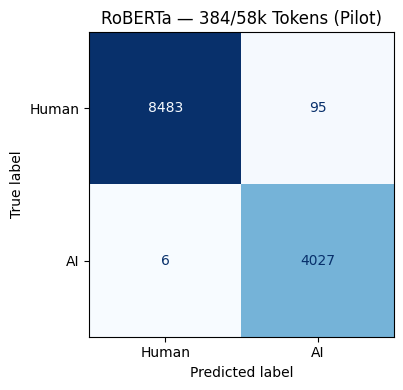

In [79]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Get predictions from our trained 384/58k-token model
predictions_384_58 = trainer.predict(tokenized_val)

y_true_384_58 = predictions_384_58.label_ids
y_pred_384_58 = np.argmax(predictions_384_58.predictions, axis=1)

# Build the confusion matrix
cm_384_58k = confusion_matrix(
    y_true_384_58,
    y_pred_384_58,
    labels=[0, 1]
)

# Display
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay(
    confusion_matrix=cm_384_58k,
    display_labels=["Human", "AI"]
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")

ax.set_title("RoBERTa — 384/58k Tokens (Pilot)")
plt.tight_layout()
plt.show()

In [80]:
results_384_58k = eval_results.copy()

print("Saved 384-58k token baseline:")
print("Accuracy:", results_384_58k["eval_accuracy"])
print("Macro F1:", results_384_58k["eval_macro_f1"])
print("Human FPR:", results_384_58k["eval_human_fpr"])

print("Confusion matrix:")
print(cm_384_58k)

Saved 384-58k token baseline:
Accuracy: 0.9919911188644834
Macro F1: 0.9908485534901093
Human FPR: 0.011074842620657496
Confusion matrix:
[[8483   95]
 [   6 4027]]


## Confusion Matrix

In [64]:
import json
from pathlib import Path

# Keep results in memory
results_384_58k = eval_results.copy()

# Save metrics and confusion matrix together
results_to_save = {
    "experiment": "roberta_384_58k",
    "max_length": 384,
    "training_samples": 58823,
    "validation_samples": 12611,
    "metrics": results_384_58k,
    "confusion_matrix": cm_384_58k.tolist()
}

output_path = (
    PROJECT_ROOT / "models" / "roberta" / "roberta_384_58k_results.json"
)

with open(output_path, "w") as f:
    json.dump(results_to_save, f, indent=4)

print("Saved results to:", output_path)
print("Accuracy:", results_384_58k["eval_accuracy"])
print("Macro F1:", results_384_58k["eval_macro_f1"])
print("Human FPR:", results_384_58k["eval_human_fpr"])
print("Confusion matrix:")
print(cm_384_58k)

Saved results to: /content/drive/MyDrive/chewy-colab/models/roberta/roberta_384_10k_results.json
Accuracy: 0.9925
Macro F1: 0.9914289412085364
Human FPR: 0.010294117647058823
Confusion matrix:
[[1346   14]
 [   1  639]]


## ROC-AUC

In [81]:
import numpy as np
from scipy.special import softmax
from sklearn.metrics import roc_auc_score

predictions = trainer.predict(tokenized_val)

# Convert model logits into probabilities
ai_probabilities = softmax(predictions.predictions, axis=1)[:, 1]

# Calculate ROC-AUC using the actual labels
roc_auc = roc_auc_score(
    predictions.label_ids,
    ai_probabilities
)

print(f"Full dataset ROC-AUC: {roc_auc:.6f}")

Full dataset ROC-AUC: 0.999828


## Save and export model

In [84]:
from pathlib import Path

MODEL_SAVE_DIR = PROJECT_ROOT / "models" / "roberta" / "roberta_384_58k"

# Existing results JSON
results_path = (
    PROJECT_ROOT / "models" / "Roberta" / "Roberta_384_58k_results.json"
)

MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Save fine-tuned model
trainer.save_model(str(MODEL_SAVE_DIR))
# Save tokenizer
tokenizer.save_pretrained(str(MODEL_SAVE_DIR))

print("Model saved to:", MODEL_SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/drive/MyDrive/chewy-colab/models/roberta/roberta_384_58k


In [85]:
import json

MODEL_SAVE_DIR = (
    PROJECT_ROOT / "models" / "roberta" / "roberta_384_58k"
)

results = {
    "accuracy": 0.9919911188644834,
    "macro_f1": 0.9908485534901093,
    "human_fpr": 0.011074842620657496,
    "roc_auc": float(roc_auc),
    "confusion_matrix": [
        [8483, 95],
        [6, 4027]
    ],
    "training_examples": 58823,
    "validation_examples": 12611,
    "max_length": 384
}

with open(MODEL_SAVE_DIR / "results.json", "w") as f:
    json.dump(results, f, indent=4)

print(f"Saved to: {MODEL_SAVE_DIR / 'results.json'}")
print(f"ROC-AUC: {results['roc_auc']:.6f}")

Saved to: /content/drive/MyDrive/chewy-colab/models/roberta/roberta_384_58k/results.json
ROC-AUC: 0.999828
